# Predicción de recaída en depresión con PHQ-9

Proyecto de aprendizaje automático con datos simulados.

> Datos ficticios. El PHQ-9 es una herramienta de cribado, no un diagnóstico. No usar datos de pacientes identificables.

El objetivo es estimar la probabilidad de recaída a 6 meses con una regresión logística. Es un modelo simple e interpretable.

## 1. Librerías

Se importan las librerías para manipular datos, entrenar el modelo y generar gráficos.

In [1]:
# Librerías para datos, modelo y gráficos
%pip install -q pandas scikit-learn matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix

SEMILLA = 42
print('Librerías listas.')


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Librerías listas.


## 2. Datos simulados

Se generan 300 pacientes ficticios. La variable objetivo es `recaida_6m`: 1 si hubo recaída en los primeros 6 meses y 0 si no. Para el ejercicio, se marca como recaída al 20% con mayor riesgo simulado.

In [2]:
# Generamos 300 pacientes ficticios
rng = np.random.default_rng(SEMILLA)
n = 300

datos = pd.DataFrame({
    'edad': rng.integers(18, 71, n),
    'sexo_femenino': rng.integers(0, 2, n),
    'phq9_alta': rng.integers(0, 10, n),
    'episodios_previos': rng.integers(0, 6, n),
    'adherencia': rng.integers(0, 11, n),
    'apoyo_social': rng.integers(0, 11, n),
    'horas_sueno': rng.uniform(4, 9, n).round(1),
})

# Calculamos un puntaje de riesgo simulado
riesgo = (
    0.8 * datos['phq9_alta']
    + 0.6 * datos['episodios_previos']
    - 0.5 * datos['adherencia']
    - 0.4 * datos['apoyo_social']
    - 0.3 * (datos['horas_sueno'] - 6)
    + rng.normal(0, 2, n)
)

# Marcamos como recaída al 20% con mayor riesgo
datos['recaida_6m'] = (riesgo > np.quantile(riesgo, 0.8)).astype(int)

# Mostramos las primeras filas y el conteo de la variable objetivo
display(datos.head())
display(datos['recaida_6m'].value_counts().rename('pacientes'))

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,recaida_6m
0,22,0,6,0,9,5,6.3,0
1,59,1,7,0,5,2,5.3,0
2,52,0,7,1,10,2,4.2,1
3,41,1,1,5,8,3,6.4,0
4,40,1,8,2,7,6,8.8,0


recaida_6m
0    240
1     60
Name: pacientes, dtype: int64

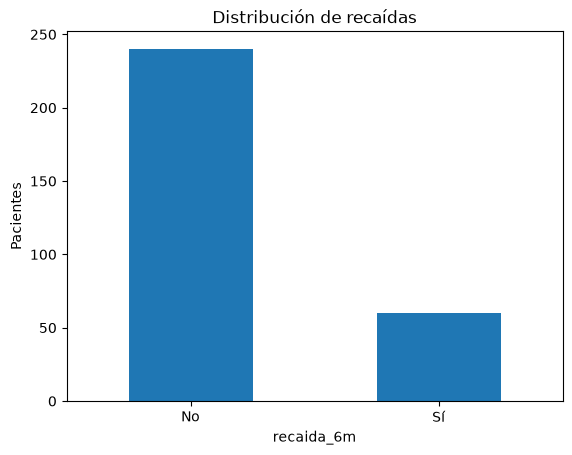

In [3]:
# Graficamos cuántos pacientes recayeron
datos['recaida_6m'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribución de recaídas')
plt.xlabel('recaida_6m')
plt.ylabel('Pacientes')
plt.xticks([0, 1], ['No', 'Sí'], rotation=0)
plt.show()

Hay 60 pacientes con recaída y 240 sin recaída.

## 3. Exploración

Se comparan los promedios de algunas variables según el resultado.

,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno
recaida_6m,,,,,
0,4.12,2.41,5.53,5.38,6.58
1,6.77,2.98,3.20,3.13,6.46


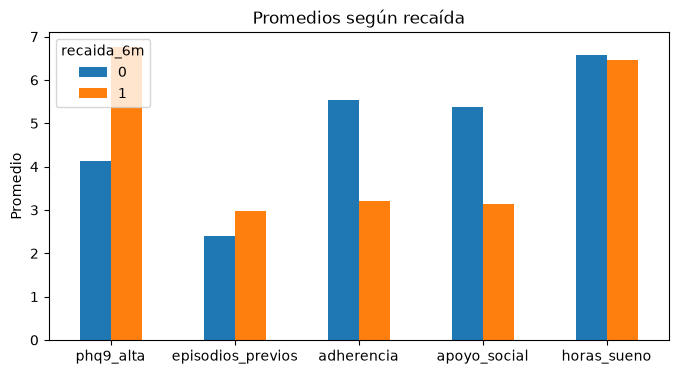

In [4]:
# Comparamos promedios entre pacientes con y sin recaída
promedios = datos.groupby('recaida_6m')[
    ['phq9_alta', 'episodios_previos', 'adherencia', 'apoyo_social', 'horas_sueno']
].mean().round(2)
display(promedios)

# Graficamos los promedios
promedios.T.plot(kind='bar', figsize=(8, 4))
plt.title('Promedios según recaída')
plt.ylabel('Promedio')
plt.xticks(rotation=0)
plt.show()

Los pacientes con recaída presentan, en promedio, mayor PHQ-9 al alta y más episodios previos. También muestran menor adherencia y menor apoyo social.

## 4. División de datos

Se separan los datos en 80% para entrenamiento y 20% para prueba. La estratificación mantiene la proporción de recaídas en ambos grupos.

In [5]:
# Separamos las variables predictoras y la variable objetivo
X = datos.drop(columns='recaida_6m')
y = datos['recaida_6m']

# Dividimos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)

print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

Entrenamiento: (240, 7)
Prueba: (60, 7)


## 5. Modelo

Se estandarizan las variables y se entrena una regresión logística.

In [6]:
# Estandarizamos las variables
escalador = StandardScaler()
X_train_esc = escalador.fit_transform(X_train)
X_test_esc = escalador.transform(X_test)

# Entrenamos la regresión logística
modelo = LogisticRegression(max_iter=1000)
modelo.fit(X_train_esc, y_train)

# Predecimos la clase y la probabilidad
pred = modelo.predict(X_test_esc)
proba = modelo.predict_proba(X_test_esc)[:, 1]

## 6. Evaluación

Se calculan exactitud, ROC-AUC, matriz de confusión y sensibilidad.

In [7]:
# Calculamos las métricas
exactitud = accuracy_score(y_test, pred)
roc_auc = roc_auc_score(y_test, proba)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
sensibilidad = tp / (tp + fn)

print('Exactitud:', round(exactitud, 2))
print('ROC-AUC:', round(roc_auc, 2))
print('Sensibilidad:', round(sensibilidad, 2))
print('Matriz de confusión:')
print(confusion_matrix(y_test, pred))

Exactitud: 0.83
ROC-AUC: 0.86
Sensibilidad: 0.5
Matriz de confusión:
[[44  4]
 [ 6  6]]


El modelo obtiene una exactitud de 0.83 y un ROC-AUC de 0.86. La matriz de confusión muestra 6 recaídas detectadas y 6 no detectadas.

## 7. Coeficientes

Los coeficientes indican la dirección del efecto de cada variable. Un valor positivo aumenta el riesgo; uno negativo lo reduce.

apoyo_social        -1.31
adherencia          -1.18
edad                -0.14
sexo_femenino        0.00
horas_sueno          0.02
episodios_previos    0.51
phq9_alta            1.62
dtype: float64

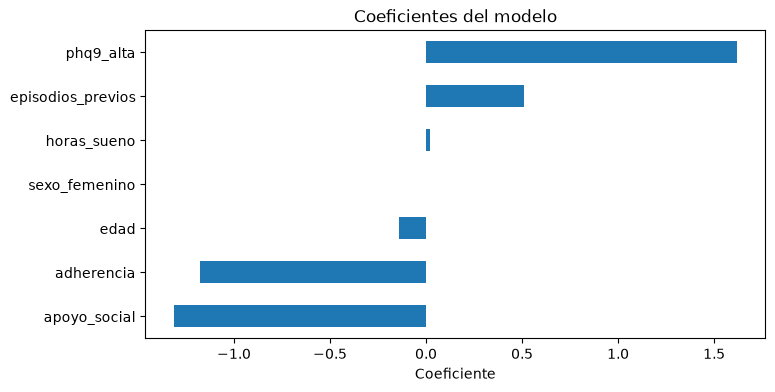

In [8]:
# Obtenemos y ordenamos los coeficientes
coeficientes = pd.Series(modelo.coef_[0], index=X.columns).sort_values()
display(coeficientes.round(2))

# Graficamos los coeficientes
coeficientes.plot(kind='barh', figsize=(8, 4))
plt.title('Coeficientes del modelo')
plt.xlabel('Coeficiente')
plt.show()

`phq9_alta` y `episodios_previos` aumentan el riesgo. `adherencia` y `apoyo_social` lo reducen.

## 8. Paciente nuevo

Se estima el riesgo para dos pacientes de ejemplo.

In [9]:
# Creamos dos pacientes nuevos
nuevo = pd.DataFrame({
    'edad': [35, 52],
    'sexo_femenino': [1, 0],
    'phq9_alta': [8, 3],
    'episodios_previos': [4, 1],
    'adherencia': [4, 9],
    'apoyo_social': [3, 8],
    'horas_sueno': [5.5, 7.5],
})

# Estandarizamos con el mismo escalador y calculamos el riesgo
nuevo_esc = escalador.transform(nuevo)
nuevo['riesgo'] = modelo.predict_proba(nuevo_esc)[:, 1].round(2)

# Clasificamos con un umbral de 0.5
nuevo['mensaje'] = nuevo['riesgo'].apply(
    lambda p: 'Riesgo alto' if p >= 0.5 else 'Riesgo bajo'
)
display(nuevo)

,edad,sexo_femenino,phq9_alta,episodios_previos,adherencia,apoyo_social,horas_sueno,riesgo,mensaje
0,35,1,8,4,4,3,5.5,0.75,Riesgo alto
1,52,0,3,1,9,8,7.5,0.00,Riesgo bajo


El primer paciente presenta mayor riesgo. La probabilidad es orientativa y no reemplaza el juicio clínico.

## 9. Ejercicios

1. Cambiar el umbral de 0.5 a 0.4 y observar la sensibilidad.
2. Quitar `adherencia` y comparar el ROC-AUC.
3. Probar `LogisticRegression(class_weight='balanced')`.
4. Cambiar el tamaño de prueba a 30%.

## 10. Errores comunes

- Entrenar y evaluar con los mismos datos.
- Mirar solo la exactitud cuando hay pocas recaídas.
- Confundir probabilidad con certeza.
- Usar datos reales sin anonimizar.

## 11. Conclusión

Se construyó un modelo simple para estimar la probabilidad de recaída a 6 meses. El ejercicio muestra el flujo básico de un proyecto de clasificación: datos, exploración, entrenamiento, evaluación e interpretación.

In [10]:
# Verificamos que el proyecto terminó correctamente
assert len(datos) == 300
assert datos['recaida_6m'].sum() == 60
assert len(X_train) + len(X_test) == 300
print('Verificación correcta.')

Verificación correcta.
